# EDA: FAR-Trans

Разведочный анализ данных. Здесь только анализ; вся логика проекта живёт в `src/farrec`,
ноутбук использует те же функции загрузки, что и пайплайн.

Что ищем: странности в данных, которые сломали бы оценку (снапшоты, дубли, утечки), и свойства,
которые определяют постановку задачи (доля повторных покупок, связь профиля с поведением).

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from farrec.data import load, customer_profile_asof
from farrec.risk import asset_risk_levels, stale_share

BLUE, ORANGE, AQUA, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#e6e5e0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True, "figure.dpi": 110})
pd.set_option("display.width", 160)
cfg = yaml.safe_load(open(ROOT / "configs/base.yaml"))
ft = load(ROOT / cfg["data"]["raw_dir"])
raw_tx = pd.read_csv(ROOT / cfg["data"]["raw_dir"] / "transactions.csv", parse_dates=["timestamp"])

## 1. Размеры таблиц

In [2]:
pd.DataFrame({
    "строк": [len(raw_tx), len(ft.customers), len(ft.assets), len(ft.prices)],
    "уникальных ключей": [raw_tx.transactionID.nunique(), ft.customers.customerID.nunique(),
                          ft.assets.ISIN.nunique(), ft.prices.ISIN.nunique()],
    "период": [f"{raw_tx.timestamp.min().date()} .. {raw_tx.timestamp.max().date()}",
               f"{ft.customers.timestamp.min().date()} .. {ft.customers.timestamp.max().date()}", "-",
               f"{ft.prices.timestamp.min().date()} .. {ft.prices.timestamp.max().date()}"],
}, index=["transactions", "customers", "assets", "close_prices"])

,строк,уникальных ключей,период
transactions,388048,359128,2018-01-02 .. 2022-11-30
customers,32468,29090,2000-01-01 .. 2022-11-30
assets,806,806,-
close_prices,703303,807,2018-01-01 .. 2022-11-29


## 2. Снапшот стартовых портфелей

2 января 2018 года — десятки тысяч «покупок» за один день. Это выгрузка портфелей на начало периода,
а не решения клиентов. Если считать их покупками, популярность и таргет исказятся.

2018-01-02: 35686 покупок; медиана по дням: 122


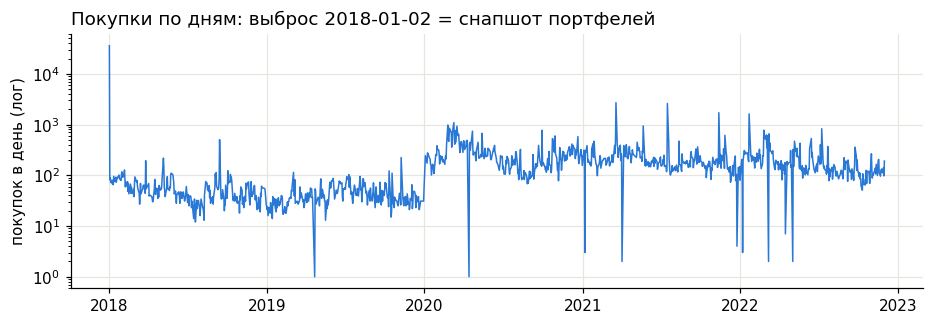

In [3]:
buys = raw_tx[raw_tx.transactionType == "Buy"]
daily = buys.groupby("timestamp").size()
print("2018-01-02:", daily.get(pd.Timestamp("2018-01-02")), "покупок; медиана по дням:", int(daily.median()))
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(daily.index, daily.values, color=BLUE, lw=1)
ax.set_yscale("log"); ax.set_ylabel("покупок в день (лог)")
ax.set_title("Покупки по дням: выброс 2018-01-02 = снапшот портфелей", loc="left")
plt.show()

## 3. Неуникальный transactionID: совместные счета

Одна и та же сделка записана на нескольких клиентов. Полных дублей строк нет, поэтому удалять по ID нельзя.

In [4]:
dup = raw_tx[raw_tx.transactionID.duplicated(keep=False)]
print("строк с повторяющимся ID:", len(dup), "| полных дублей строк:", raw_tx.duplicated().sum())
print("клиентов на один ID:", dup.groupby("transactionID").customerID.nunique().value_counts().to_dict())
dup.sort_values("transactionID").head(4)

строк с повторяющимся ID: 52308 | полных дублей строк: 0
клиентов на один ID: {2: 19109, 3: 3132, 4: 1041, 5: 106}


,customerID,ISIN,transactionID,transactionType,timestamp,totalValue,units,channel,marketID
210598,058E9BA5E5164DA9C180,GRF000023009,6114955,Buy,2018-01-02,4999.980572,225.051,Branch,AEDAK
212258,D81F2638A9D9E5834D37,GRF000023009,6114955,Buy,2018-01-02,4999.980572,225.051,Branch,AEDAK
150304,FBCE9AAC6E1F4C728449,GRS015003007,6124377,Sell,2018-01-03,40.480000,22.000,Phone Banking,XATH
146659,DFC7DF3238EC72B1597E,GRS015003007,6124377,Sell,2018-01-03,40.480000,22.000,Phone Banking,XATH


## 4. Что покупают и как часто

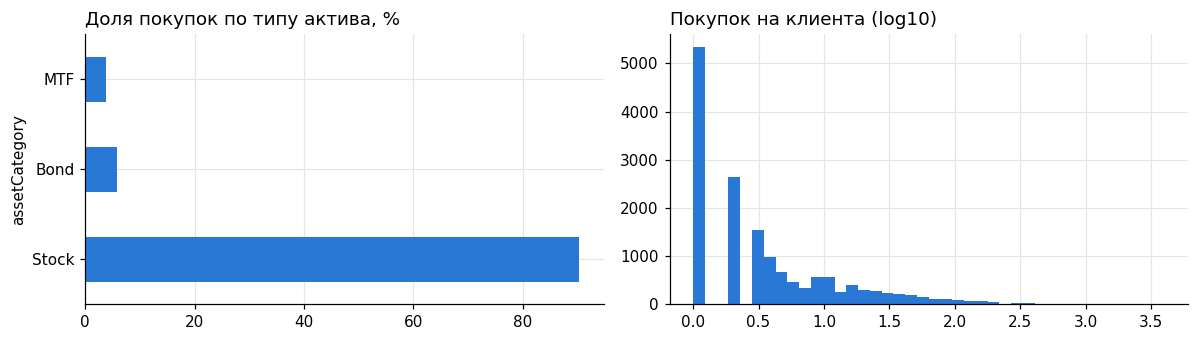

{'count': 15744.0, 'mean': 12.3, 'std': 54.5, 'min': 1.0, '50%': 2.0, '90%': 24.0, '99%': 165.0, 'max': 4009.0}


In [5]:
b = ft.buys.merge(ft.assets[["ISIN", "assetCategory"]], on="ISIN", how="left")
per_cust = b.groupby("customerID").size()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
b.assetCategory.value_counts(normalize=True).mul(100).plot.barh(ax=axes[0], color=BLUE)
axes[0].set_title("Доля покупок по типу актива, %", loc="left")
axes[1].hist(np.log10(per_cust), bins=40, color=BLUE)
axes[1].set_title("Покупок на клиента (log10)", loc="left")
plt.tight_layout(); plt.show()
print(per_cust.describe(percentiles=[.5, .9, .99]).round(1).to_dict())

## 5. Повторные покупки

Главное свойство задачи: большинство покупок — докупка того, что клиент уже покупал. Поэтому
модели нужно оценивать отдельно на новых для клиента активах.

In [6]:
rows = []
t = ft.transactions
for c in pd.date_range("2020-06-01", "2022-09-01", freq="3MS"):
    w = ft.buys[(ft.buys.timestamp >= c) & (ft.buys.timestamp < c + pd.Timedelta(days=60))][["customerID", "ISIN"]].drop_duplicates()
    seen = t[(t.transactionType == "Buy") & (t.timestamp < c)][["customerID", "ISIN"]].drop_duplicates()
    rows.append({"cutoff": c.date(), "repeat_share": len(w.merge(seen)) / len(w)})
pd.DataFrame(rows).set_index("cutoff").round(3).T

cutoff,2020-06-01,2020-09-01,2020-12-01,2021-03-01,2021-06-01,2021-09-01,2021-12-01,2022-03-01,2022-06-01,2022-09-01
repeat_share,0.659,0.574,0.604,0.435,0.393,0.527,0.484,0.728,0.633,0.792


## 6. Профили клиентов заполнены задним числом (утечка)

Риск-профиль не меняется ни у одного клиента, а дата последней анкеты часто позже даты самой строки профиля.
То есть профиль отражает итоговое состояние, а не состояние на дату. Признак «дней с анкеты» отсюда убран.

In [7]:
cu = ft.customers
print("клиентов с >1 строкой:", (cu.customerID.value_counts() > 1).sum(),
      "| у скольких менялся риск-профиль:", (cu.groupby("customerID").riskLevel.nunique() > 1).sum())
print("строк, где анкета позже даты строки:", f"{(cu.lastQuestionnaireDate > cu.timestamp).mean():.1%}")
cu[cu.lastQuestionnaireDate > cu.timestamp][["customerID", "riskLevel", "lastQuestionnaireDate", "timestamp"]].head(3)

клиентов с >1 строкой: 2263 | у скольких менялся риск-профиль: 0
строк, где анкета позже даты строки: 38.5%


,customerID,riskLevel,lastQuestionnaireDate,timestamp
135,00090203A8C62E135D0B,Income,2021-05-18,2018-01-02
136,001270E70A4ECA1CD664,Balanced,2018-05-24,2018-01-02
137,0017D195DFD87A91C59D,Conservative,2021-04-21,2018-01-02


## 7. Профиль почти не влияет на поведение

Даже консерваторы в основном покупают отдельные акции с волатильностью выше 25% (уровень 7).
Поэтому допустимые уровни риска задаются политикой, а не калибруются по данным.

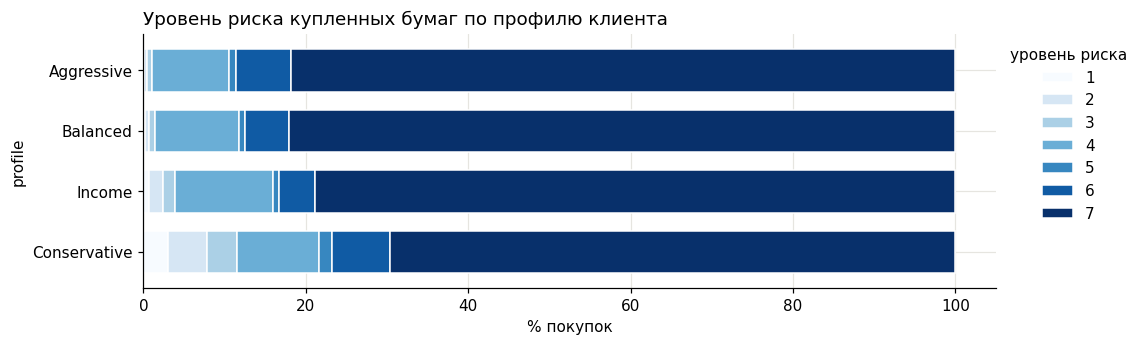

level,1,2,3,4,5,6,7
profile,,,,,,,
Conservative,0.030,0.049,0.037,0.101,0.015,0.072,0.697
Income,0.007,0.017,0.015,0.121,0.008,0.044,0.789
Balanced,0.002,0.006,0.007,0.103,0.008,0.053,0.821
Aggressive,0.001,0.003,0.007,0.095,0.009,0.067,0.819


In [8]:
parts = []
for c in pd.date_range("2021-01-01", "2022-07-01", freq="3MS"):
    lvl = asset_risk_levels(ft.prices, ft.assets, c, cfg["risk"]["srri_bounds"])
    w = ft.buys[(ft.buys.timestamp >= c) & (ft.buys.timestamp < c + pd.Timedelta(days=90))]
    prof = customer_profile_asof(ft.customers, c + pd.Timedelta(days=90)).riskLevel
    parts.append(pd.DataFrame({"profile": w.customerID.map(prof), "level": w.ISIN.map(lvl)}))
d = pd.concat(parts).dropna()
order = ["Conservative", "Income", "Balanced", "Aggressive"]
d = d[d.profile.isin(order)]
tab = pd.crosstab(d.profile, d.level, normalize="index").reindex(order)
ax = tab.mul(100).plot.barh(stacked=True, figsize=(10, 3), colormap="Blues", edgecolor="white", width=0.7)
ax.set_xlabel("% покупок"); ax.legend(title="уровень риска", bbox_to_anchor=(1, 1), frameon=False)
ax.set_title("Уровень риска купленных бумаг по профилю клиента", loc="left")
plt.show(); tab.round(3)

## 8. Замороженные цены: приостановленные акции выглядят самыми безопасными

У акций, торги которыми приостановлены, цена не меняется, волатильность нулевая, и формула даёт уровень риска 1.
Правило в `risk.py`: акция с >50% дней без изменения цены получает уровень 7 (риск неизвестен).

In [9]:
c = pd.Timestamp("2022-09-01")
st = stale_share(ft.prices, c)
a = ft.assets.set_index("ISIN")
frozen = st[(st > 0.5) & (st.index.map(a.assetCategory) == "Stock")].sort_values(ascending=False)
print("акций с замороженной ценой на", c.date(), ":", len(frozen))
pd.DataFrame({"доля дней без изменения": frozen.round(2), "название": frozen.index.map(a.assetName)}).head(8)

акций с замороженной ценой на 2022-09-01 : 49


,доля дней без изменения,название
ISIN,,
GRS182003004,0.99,AEGEK (CR)
GRS316007004,0.99,"ANEK LINES S.A. (PR, issue '90)"
GRS301003000,0.99,VARANGIS AVEPE S.A.
GRS422003004,0.99,MLS INNOVATION INC
GRS339003022,0.99,DIONIC S.A. (CR)
GRS294003009,0.99,FOLLIE FOLLIE GROUP (CR)
GRS250073004,0.99,ELVIEMEK LAND DEVELOMPENT-LOGISTICS PARKS-ENER...
GRS254183007,0.99,G.E. DIMITRIOU S.A.(CR)


## Выводы для постановки

* Снапшот 2018-01-02 исключаем из покупок, но учитываем в портфелях.
* Совместные счета: дедупликация только по полной строке.
* Большинство покупок повторные → отдельные метрики на новых активах.
* Профиль статичен и заполнен задним числом → используем как атрибут, без признаков давности анкеты.
* Профиль почти не влияет на покупки → лимиты риска задаются политикой; кривая компромисса показывает их цену.
* Замороженные акции → уровень риска 7.